In [1]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, SimpleRNN, Dense

In [2]:
data = np.array([
    25,27,29,31,33,
    35,37,39,41,43,
    45,47,49,51,53,
    55,57,59,61,63
])

In [3]:
# prepare  input and output

x = []
y = []

for i in range(len(data) - 3):
    x.append(data[i:i+3])
    y.append(data[i+3])

x = np.array(x)
y = np.array(y)

In [4]:
# Reshape input

x = x.reshape(x.shape[0], x.shape[1], 1)

In [5]:
# Build RNN Model

model = Sequential([
    Input(shape=(3,1)),
    SimpleRNN(32, activation='tanh'),
    Dense(1)
])

In [6]:
# model compile

model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         1,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,121 (4.38 KB)

 Trainable params: 1,121 (4.38 KB)

 Non-trainable params: 0 (0.00 B)

In [8]:
history = model.fit(
    x,
    y,
    epochs=100,
    batch_size=4,
    verbose=1
)

Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 15ms/step - loss: 2347.6023 - mae: 47.4523
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 2326.1301 - mae: 47.2119
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 2301.9487 - mae: 46.9545
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2275.3562 - mae: 46.6671
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2246.5449 - mae: 46.3562
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 2216.6697 - mae: 46.0378
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 2188.8616 - mae: 45.7344
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 2163.8833 - mae: 45.4526
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 2139.5500 - mae: 45.1886
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2114.7866 - mae: 44.9078
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 2086.6079 - mae: 44.5828
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2054.9482 - mae: 44.2242
E

In [9]:
last_sequence = np.array([61,63,65]).reshape(1,3,1)

prediction = model.predict(last_sequence)

print(prediction[0][0])

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step
16.924593


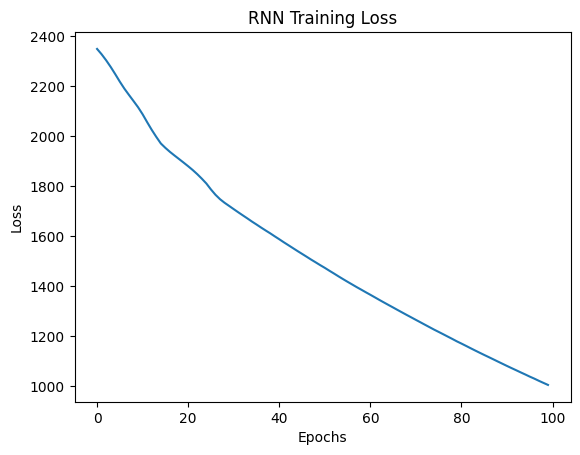

In [10]:
plt.plot(history.history['loss'])
plt.title("RNN Training Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.show()